Name: Ivy Cheng

Github Username: ivychengusc

USC ID: 6931463618

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### 1(a)

In [2]:
TRAIN_PATH = "../data/Homework 6 Data/aps_failure_training_set.csv"
TEST_PATH = "../data/Homework 6 Data/aps_failure_test_set.csv"

train_df = pd.read_csv(
    TRAIN_PATH,
    skiprows=20,
    na_values="na"
)

test_df = pd.read_csv(
    TEST_PATH,
    skiprows=20,
    na_values="na"
)

print("Training set shape:", train_df.shape)
print("Test set shape:", test_df.shape)

train_df.head()

Training set shape: (60000, 171)
Test set shape: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### 1(b)(i)

In [3]:
X_train = train_df.drop(columns=["class"])
y_train = train_df["class"]

X_test = test_df.drop(columns=["class"])
y_test = test_df["class"]

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

print("Missing values before imputation:", X_train.isna().sum().sum())
print("Missing values after imputation:", X_train_imputed.isna().sum().sum())

Missing values before imputation: 850015
Missing values after imputation: 0


### 1(b)(ii)

In [4]:
feature_means = X_train_imputed.mean()
feature_stds = X_train_imputed.std(ddof=1)

cv_values = feature_stds / feature_means

cv_table = pd.DataFrame({
    "Mean": feature_means,
    "Standard Deviation": feature_stds,
    "CV": cv_values
}).sort_values("CV", ascending=False)

print("Number of features:", len(cv_table))
cv_table.head(10)

Number of features: 170


,Mean,Standard Deviation,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


### 1(b)(iii)

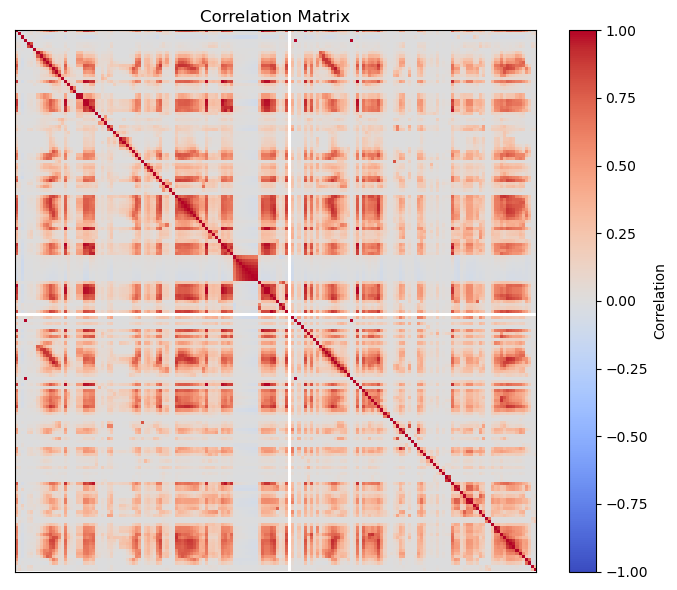

In [5]:
correlation_matrix = X_train_imputed.corr()

plt.figure(figsize=(7, 6))
plt.imshow(
    correlation_matrix,
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.colorbar(label="Correlation")
plt.title("Correlation Matrix")
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()

### 1(b)(iv)

In [6]:
num_features = int(np.floor(np.sqrt(170)))
top_cv_features = cv_table.head(num_features).index.tolist()

print("Selected features:", ", ".join(top_cv_features))

Selected features: cf_000, co_000, ad_000, cs_009, dh_000, dj_000, ag_000, as_000, ay_009, ak_000, az_009, ch_000, au_000


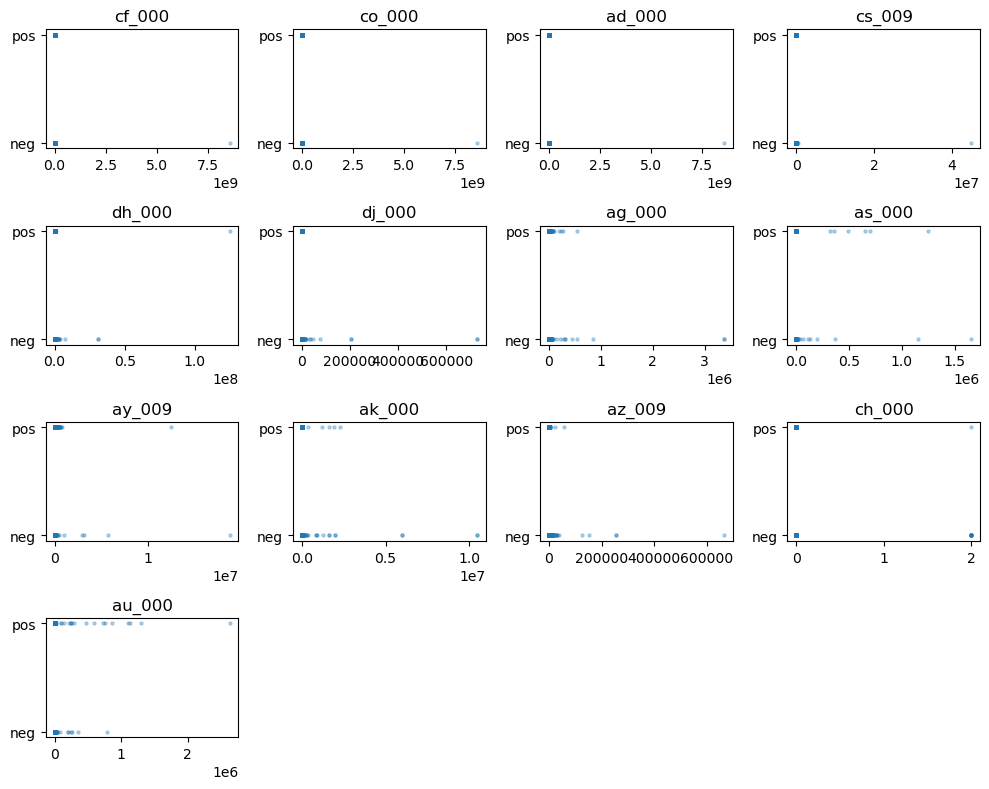

In [7]:
y_numeric = y_train.map({"neg": 0, "pos": 1})

fig, axes = plt.subplots(4, 4, figsize=(10, 8))
axes = axes.flatten()

for i, feature in enumerate(top_cv_features):
    axes[i].scatter(
        X_train_imputed[feature],
        y_numeric,
        s=5,
        alpha=0.3
    )
    axes[i].set_title(feature)
    axes[i].set_yticks([0, 1])
    axes[i].set_yticklabels(["neg", "pos"])

for i in range(len(top_cv_features), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

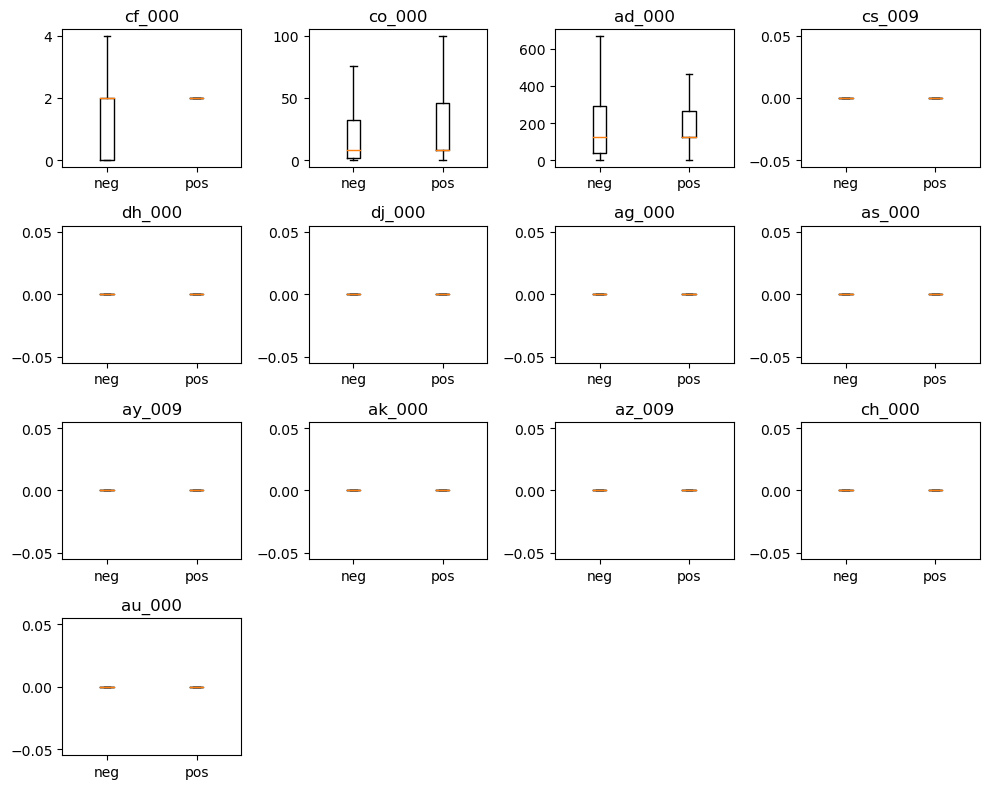

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(10, 8))
axes = axes.flatten()

for i, feature in enumerate(top_cv_features):
    neg_values = X_train_imputed.loc[y_train == "neg", feature]
    pos_values = X_train_imputed.loc[y_train == "pos", feature]

    axes[i].boxplot(
        [neg_values, pos_values],
        labels=["neg", "pos"],
        showfliers=False
    )
    axes[i].set_title(feature)

for i in range(len(top_cv_features), len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

The scatter plots and box plots show some differences between the positive and negative classes for several features. However, statistical significance cannot be determined from these plots alone. A statistical test or predictive model would be needed to determine whether the features are significant.

### 1(b)(v)

In [9]:
class_counts = y_train.value_counts()

print("Negative:", class_counts["neg"])
print("Positive:", class_counts["pos"])

imbalance_ratio = class_counts["neg"] / class_counts["pos"]
print("Negative-to-positive ratio:", imbalance_ratio)

Negative: 59000
Positive: 1000
Negative-to-positive ratio: 59.0


The training set is highly imbalanced, with about 59 negative observations for every positive observation.

### 1(c)

In [10]:
y_train_num = y_train.map({"neg": 0, "pos": 1})
y_test_num = y_test.map({"neg": 0, "pos": 1})

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=552,
    oob_score=True,
    n_jobs=-1
)

rf_model.fit(X_train_imputed, y_train_num)

train_pred = rf_model.predict(X_train_imputed)
test_pred = rf_model.predict(X_test_imputed)

train_prob = rf_model.predict_proba(X_train_imputed)[:, 1]
test_prob = rf_model.predict_proba(X_test_imputed)[:, 1]

In [11]:
train_cm = confusion_matrix(y_train_num, train_pred)
test_cm = confusion_matrix(y_test_num, test_pred)

print("Training Confusion Matrix:")
print(train_cm)

print("\nTest Confusion Matrix:")
print(test_cm)

Training Confusion Matrix:
[[59000     0]
 [    0  1000]]

Test Confusion Matrix:
[[15606    19]
 [  102   273]]


In [12]:
train_auc = roc_auc_score(y_train_num, train_prob)
test_auc = roc_auc_score(y_test_num, test_prob)

train_error = np.mean(train_pred != y_train_num)
test_error = np.mean(test_pred != y_test_num)

oob_error = 1 - rf_model.oob_score_

rf_results = pd.DataFrame({
    "Set": ["Training", "Test"],
    "AUC": [train_auc, test_auc],
    "Misclassification Error": [train_error, test_error]
})

rf_results

,Set,AUC,Misclassification Error
0,Training,1.00000,0.000000
1,Test,0.99439,0.007562


In [13]:
print("OOB Error:", oob_error)
print("Test Error:", test_error)

OOB Error: 0.005800000000000027
Test Error: 0.0075625


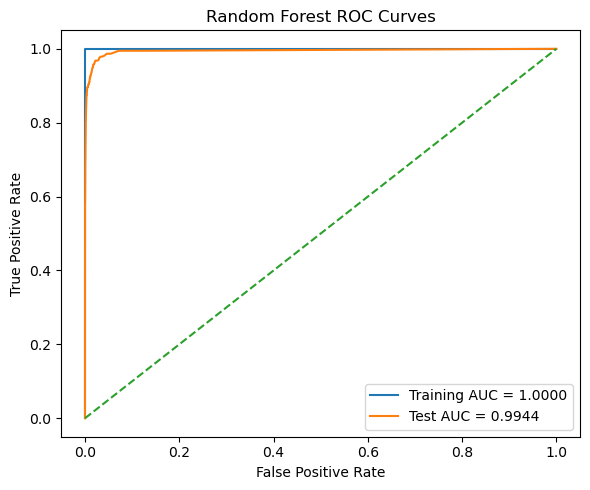

In [14]:
train_fpr, train_tpr, _ = roc_curve(y_train_num, train_prob)
test_fpr, test_tpr, _ = roc_curve(y_test_num, test_prob)

plt.figure(figsize=(6, 5))

plt.plot(train_fpr, train_tpr, label=f"Training AUC = {train_auc:.4f}")
plt.plot(test_fpr, test_tpr, label=f"Test AUC = {test_auc:.4f}")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

The random forest has a training AUC of 1.0000 and a test AUC of 0.9944. The training error is 0, while the test error is 0.0076. The OOB error is 0.0058, which is close to the test error, indicating that the OOB estimate is a reasonable estimate of test performance.

### 1(d)

In [15]:
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=552,
    oob_score=True,
    n_jobs=-1
)

rf_balanced.fit(X_train_imputed, y_train_num)

train_pred_bal = rf_balanced.predict(X_train_imputed)
test_pred_bal = rf_balanced.predict(X_test_imputed)

train_prob_bal = rf_balanced.predict_proba(X_train_imputed)[:, 1]
test_prob_bal = rf_balanced.predict_proba(X_test_imputed)[:, 1]

In [16]:
train_cm_bal = confusion_matrix(y_train_num, train_pred_bal)
test_cm_bal = confusion_matrix(y_test_num, test_pred_bal)

print("Training Confusion Matrix:")
print(train_cm_bal)

print("\nTest Confusion Matrix:")
print(test_cm_bal)

Training Confusion Matrix:
[[59000     0]
 [    0  1000]]

Test Confusion Matrix:
[[15609    16]
 [  157   218]]


In [17]:
train_auc_bal = roc_auc_score(y_train_num, train_prob_bal)
test_auc_bal = roc_auc_score(y_test_num, test_prob_bal)

train_error_bal = np.mean(train_pred_bal != y_train_num)
test_error_bal = np.mean(test_pred_bal != y_test_num)

oob_error_bal = 1 - rf_balanced.oob_score_

balanced_results = pd.DataFrame({
    "Set": ["Training", "Test"],
    "AUC": [train_auc_bal, test_auc_bal],
    "Misclassification Error": [train_error_bal, test_error_bal]
})

balanced_results

,Set,AUC,Misclassification Error
0,Training,1.00000,0.000000
1,Test,0.99293,0.010812


In [18]:
comparison = pd.DataFrame({
    "Model": ["Unbalanced RF", "Balanced RF"],
    "Test AUC": [test_auc, test_auc_bal],
    "Test Error": [test_error, test_error_bal],
    "OOB Error": [oob_error, oob_error_bal]
})

comparison

,Model,Test AUC,Test Error,OOB Error
0,Unbalanced RF,0.99439,0.007562,0.005800
1,Balanced RF,0.99293,0.010812,0.007567


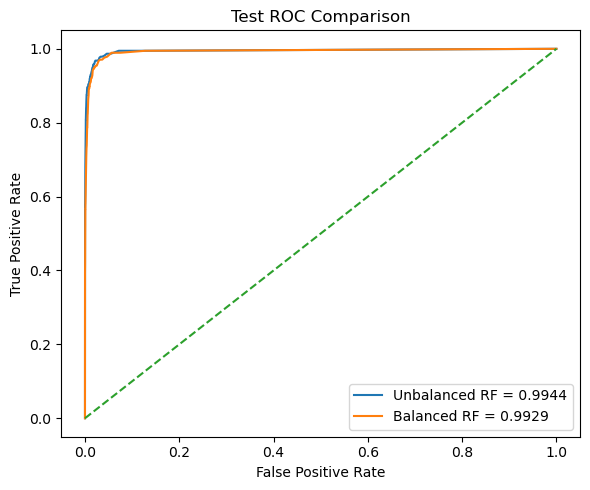

In [19]:
fpr_bal, tpr_bal, _ = roc_curve(y_test_num, test_prob_bal)

plt.figure(figsize=(6, 5))
plt.plot(test_fpr, test_tpr, label=f"Unbalanced RF = {test_auc:.4f}")
plt.plot(fpr_bal, tpr_bal, label=f"Balanced RF = {test_auc_bal:.4f}")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC Comparison")
plt.legend()
plt.tight_layout()
plt.show()

Compared with the unbalanced random forest, the balanced model has a slightly lower test AUC (0.9929 vs. 0.9944) and a higher test error (0.0108 vs. 0.0076). It also correctly identifies fewer positive cases (218 vs. 273). Therefore, class weighting did not improve performance for this dataset.

### 1(e)

In [20]:
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=200,
    max_depth=3,
    learning_rate=0.1,
    tree_method="hist",
    random_state=552,
    n_jobs=1
)

param_grid = {
    "reg_alpha": [0, 0.01, 0.1, 1, 10]
}

xgb_grid = GridSearchCV(
    xgb_model,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

_ = xgb_grid.fit(X_train_imputed, y_train_num)

best_alpha = xgb_grid.best_params_["reg_alpha"]
cv_error = 1 - xgb_grid.best_score_

print("Best alpha:", best_alpha)
print("5-fold CV error:", cv_error)

Best alpha: 0.1
5-fold CV error: 0.006216666666666648


In [21]:
xgb_best = xgb_grid.best_estimator_

train_pred_xgb = xgb_best.predict(X_train_imputed)
test_pred_xgb = xgb_best.predict(X_test_imputed)

train_prob_xgb = xgb_best.predict_proba(X_train_imputed)[:, 1]
test_prob_xgb = xgb_best.predict_proba(X_test_imputed)[:, 1]

In [22]:
train_cm_xgb = confusion_matrix(y_train_num, train_pred_xgb)
test_cm_xgb = confusion_matrix(y_test_num, test_pred_xgb)

print("Training Confusion Matrix:")
print(train_cm_xgb)

print("\nTest Confusion Matrix:")
print(test_cm_xgb)

Training Confusion Matrix:
[[58979    21]
 [  134   866]]

Test Confusion Matrix:
[[15608    17]
 [  104   271]]


In [23]:
train_auc_xgb = roc_auc_score(y_train_num, train_prob_xgb)
test_auc_xgb = roc_auc_score(y_test_num, test_prob_xgb)

train_error_xgb = np.mean(train_pred_xgb != y_train_num)
test_error_xgb = np.mean(test_pred_xgb != y_test_num)

xgb_results = pd.DataFrame({
    "Set": ["Training", "Test"],
    "AUC": [train_auc_xgb, test_auc_xgb],
    "Misclassification Error": [train_error_xgb, test_error_xgb]
})

xgb_results

,Set,AUC,Misclassification Error
0,Training,0.998565,0.002583
1,Test,0.996148,0.007562


In [24]:
print("5-fold CV Error:", cv_error)
print("Test Error:", test_error_xgb)

5-fold CV Error: 0.006216666666666648
Test Error: 0.0075625


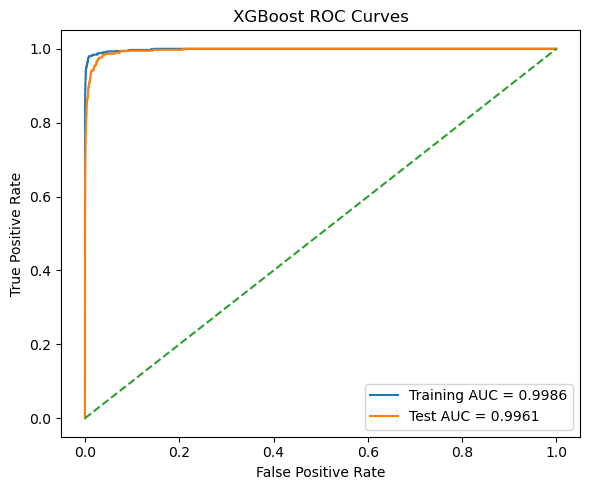

In [25]:
train_fpr_xgb, train_tpr_xgb, _ = roc_curve(
    y_train_num, train_prob_xgb
)

test_fpr_xgb, test_tpr_xgb, _ = roc_curve(
    y_test_num, test_prob_xgb
)

plt.figure(figsize=(6, 5))

plt.plot(
    train_fpr_xgb,
    train_tpr_xgb,
    label=f"Training AUC = {train_auc_xgb:.4f}"
)

plt.plot(
    test_fpr_xgb,
    test_tpr_xgb,
    label=f"Test AUC = {test_auc_xgb:.4f}"
)

plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

The best regularization parameter is $\alpha=0.1$. The 5-fold cross-validation error is 0.0062, which is close to the test error of 0.0076. The model also achieves a test AUC of 0.9961, indicating strong classification performance.

### 1(f)

In [26]:
# Use SMOTE inside each cross-validation training fold
smote_xgb = Pipeline([
    ("smote", SMOTE(random_state=552)),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=200,
        max_depth=3,
        learning_rate=0.1,
        tree_method="hist",
        random_state=552,
        n_jobs=1
    ))
])

param_grid_smote = {
    "xgb__reg_alpha": [0, 0.01, 0.1, 1, 10]
}

smote_grid = GridSearchCV(
    smote_xgb,
    param_grid_smote,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

_ = smote_grid.fit(X_train_imputed, y_train_num)

best_alpha_smote = smote_grid.best_params_["xgb__reg_alpha"]
cv_error_smote = 1 - smote_grid.best_score_

print("Best alpha:", best_alpha_smote)
print("5-fold CV error:", cv_error_smote)

/opt/anaconda3/envs/GenZest/lib/python3.10/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best alpha: 0.01
5-fold CV error: 0.013299999999999867


In [27]:
smote_best = smote_grid.best_estimator_

train_pred_smote = smote_best.predict(X_train_imputed)
test_pred_smote = smote_best.predict(X_test_imputed)

train_prob_smote = smote_best.predict_proba(X_train_imputed)[:, 1]
test_prob_smote = smote_best.predict_proba(X_test_imputed)[:, 1]

train_auc_smote = roc_auc_score(y_train_num, train_prob_smote)
test_auc_smote = roc_auc_score(y_test_num, test_prob_smote)

train_error_smote = np.mean(train_pred_smote != y_train_num)
test_error_smote = np.mean(test_pred_smote != y_test_num)

train_cm_smote = confusion_matrix(y_train_num, train_pred_smote)
test_cm_smote = confusion_matrix(y_test_num, test_pred_smote)

print("Training Confusion Matrix:")
print(train_cm_smote)

print("\nTest Confusion Matrix:")
print(test_cm_smote)

Training Confusion Matrix:
[[58398   602]
 [   64   936]]

Test Confusion Matrix:
[[15454   171]
 [   37   338]]


In [28]:
smote_results = pd.DataFrame({
    "Set": ["Training", "Test"],
    "AUC": [train_auc_smote, test_auc_smote],
    "Misclassification Error": [train_error_smote, test_error_smote]
})

smote_results

,Set,AUC,Misclassification Error
0,Training,0.997134,0.0111
1,Test,0.993715,0.0130


In [29]:
smote_comparison = pd.DataFrame({
    "Model": ["XGBoost", "XGBoost + SMOTE"],
    "Best Alpha": [best_alpha, best_alpha_smote],
    "CV Error": [cv_error, cv_error_smote],
    "Test AUC": [test_auc_xgb, test_auc_smote],
    "Test Error": [test_error_xgb, test_error_smote]
})

smote_comparison

,Model,Best Alpha,CV Error,Test AUC,Test Error
0,XGBoost,0.10,0.006217,0.996148,0.007562
1,XGBoost + SMOTE,0.01,0.013300,0.993715,0.013000


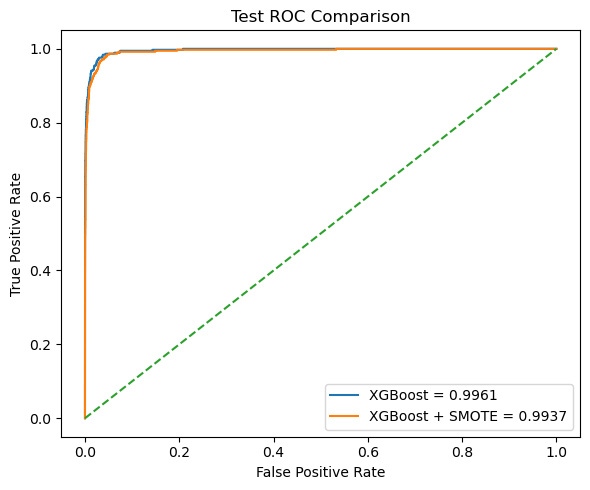

In [30]:
test_fpr_smote, test_tpr_smote, _ = roc_curve(
    y_test_num, test_prob_smote
)

plt.figure(figsize=(6, 5))

plt.plot(
    test_fpr_xgb,
    test_tpr_xgb,
    label=f"XGBoost = {test_auc_xgb:.4f}"
)

plt.plot(
    test_fpr_smote,
    test_tpr_smote,
    label=f"XGBoost + SMOTE = {test_auc_smote:.4f}"
)

plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC Comparison")
plt.legend()
plt.tight_layout()
plt.show()

With SMOTE, the best $\alpha$ is 0.01 and the test AUC is 0.9937. SMOTE increases the number of correctly classified positive cases from 271 to 338, but also increases false positives from 17 to 171. Therefore, SMOTE improves minority-class detection, but the overall test error increases from 0.0076 to 0.0130.

### 6.6.3

(a) iv. Steadily decrease.  
A larger $s$ allows a better fit to the training data, so training RSS decreases.

(b) ii. Decrease initially, then increase in a U shape.  
Test RSS first decreases as the model fits better, but may increase due to overfitting.

(c) iii. Steadily increase.  
Greater model flexibility leads to higher variance.

(d) iv. Steadily decrease.  
Greater model flexibility reduces bias.

(e) v. Remain constant.  
Irreducible error does not depend on the model or on $s$.

### 6.6.5

(a) Ridge regression:

$$
\min_{\beta_1,\beta_2}
\left[(y_1-(\beta_1+\beta_2)x_{11})^2+(y_2-(\beta_1+\beta_2)x_{21})^2
+\lambda(\beta_1^2+\beta_2^2)\right].
$$

(b) Since the predictors are identical,

$$
\frac{\partial RSS}{\partial\beta_1}
=
\frac{\partial RSS}{\partial\beta_2}.
$$

Thus,

$$
2\lambda(\hat\beta_1-\hat\beta_2)=0
\quad\Rightarrow\quad
\boxed{\hat\beta_1=\hat\beta_2}.
$$

(c) Lasso regression:

$$
\min_{\beta_1,\beta_2}
\left[(y_1-(\beta_1+\beta_2)x_{11})^2+(y_2-(\beta_1+\beta_2)x_{21})^2
+\lambda(|\beta_1|+|\beta_2|)\right].
$$

(d) Let $c=\hat\beta_1+\hat\beta_2$. The fitted values depend only on $c$, and for coefficients with the same sign,

$$
|\beta_1|+|\beta_2|=|\beta_1+\beta_2|=|c|.
$$

Hence every same-sign pair satisfying $\beta_1+\beta_2=c$ gives the same objective value. If $c>0$, $0\leq\beta_1\leq c$ and $\beta_2=c-\beta_1$; if $c<0$, $c\leq\beta_1\leq0$ and $\beta_2=c-\beta_1$. Therefore, the lasso solution is not unique.

### 8.4.5

Majority vote: 6 of the 10 probabilities exceed 0.5, so

$$
\boxed{\text{Red}}.
$$

Average probability:

$$
\frac{0.10+0.15+0.20+0.20+0.55+0.60+0.60+0.65+0.70+0.75}{10}
=0.45<0.5,
$$

so

$$
\boxed{\text{Green}}.
$$

### 9.7.3

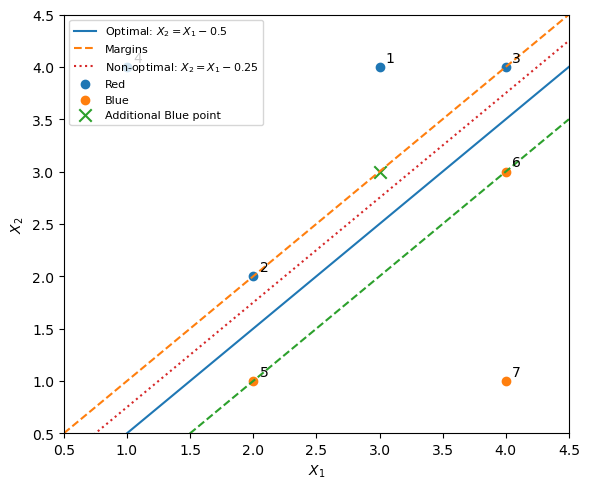

In [31]:
red = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue = np.array([[2, 1], [4, 3], [4, 1]])

plt.figure(figsize=(6, 5))

plt.scatter(red[:, 0], red[:, 1], label="Red")
plt.scatter(blue[:, 0], blue[:, 1], label="Blue")

for i, (x1, x2) in enumerate(np.vstack([red, blue]), 1):
    plt.text(x1 + 0.05, x2 + 0.05, str(i))

x = np.linspace(0.5, 4.5, 100)

plt.plot(x, x - 0.5, label="Optimal: $X_2=X_1-0.5$")

plt.plot(x, x, "--", label="Margins")
plt.plot(x, x - 1, "--")

plt.plot(x, x - 0.25, ":", label="Non-optimal: $X_2=X_1-0.25$")

plt.scatter(3, 3, marker="x", s=80, label="Additional Blue point")

plt.xlim(0.5, 4.5)
plt.ylim(0.5, 4.5)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

(a) The observations are shown above.

(b) The maximal margin hyperplane is

$$
X_2=X_1-0.5
\quad\Leftrightarrow\quad
0.5-X_1+X_2=0.
$$

(c) Classify Red if $0.5-X_1+X_2>0$, and Blue otherwise. Thus
$\beta_0=0.5,\ \beta_1=-1,\ \beta_2=1$.

(d) The margin boundaries are $X_2=X_1$ and $X_2=X_1-1$.

(e) Support vectors: observations 2, 3, 5, and 6:
$(2,2),(4,4),(2,1),(4,3)$.

(f) Observation 7, $(4,1)$, is not a support vector, so a small movement does not affect the maximal margin hyperplane.

(g) One non-optimal separating hyperplane is $X_2=X_1-0.25$.

(h) Add a Blue observation at $(3,3)$. It lies between Red observations $(2,2)$ and $(4,4)$, so the classes are no longer linearly separable.